In [1]:
import sys
sys.path.append("../")

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit.quantum_info import Statevector, SparsePauliOp
from qitp.engine.unitary_approximation import UnitaryApproximation
from qitp.engine.propagation import QITEPropagation
from qitp.engine.cqite_run import run_qite
from qitp.engine.prepare_state import constraint_rotation, prepare_state, prepare_real_state 
from qitp.simulation.backend import SimulatorBackend

In [6]:
from qitp.ansatz.pauli_basis import (
    PauliBasis
)

from qitp.ansatz.commutator_basis import (
    CommutatorBasis
)

In [10]:
depth=1
dt=1e-1
nqubits = 3

In [8]:
nsteps=50
target=0.25

energies=[]
fidelities=[]
errors=[]
magnetizations=[]

In [14]:
from qiskit.quantum_info import SparsePauliOp


J = 0.25

H = SparsePauliOp(
    [
        "ZZI",
        "ZIZ",
        "IZZ",
    ],
    coeffs=[J, J, J]
)

In [16]:
Mz = constraints = [
    SparsePauliOp(["XII"], coeffs=[1.0]),
    SparsePauliOp(["IXI"], coeffs=[1.0]),
    SparsePauliOp(["IIX"], coeffs=[1.0]),
]

Identity = SparsePauliOp(["III"],coeffs=[1.0])

In [18]:
H_eff = H + sum(Mz[1:], start=Mz[0])# + Identity

In [20]:
basis = CommutatorBasis.from_seed(hamiltonian=H_eff, seeds=seeds, depth=depth)

NameError: name 'seeds' is not defined

In [154]:
cb = CommutatorBasis.from_seed(
    H,
    seeds,
    depth=depth
)

sb = SymplecticBasis.from_operators(
    cb.paulis
)

print(
    "commutator size =",
    cb.size
)

print(
    "symplectic size =",
    sb.size
)

commutator size = 9
symplectic size = 6


In [156]:
basis = sb

In [158]:
rotations = []

for constraint in Mz:

    rotations.append(
        constraint_rotation(
            constraint,
            target
        )
    )

In [160]:
#circuit = prepare_state(
#    3,
#    rotations
#)

In [162]:
circuit, state = (
    prepare_real_state(3, target)
)

In [164]:
circuit = circuit.decompose()

In [166]:
approx = UnitaryApproximation(basis)

backend = SimulatorBackend()

prop = QITEPropagation(
    H,
    approx,
    backend,
    seeds,
    depth=depth
)

prop.constraints = [
    Identity]
prop.constraints.extend(Mz)

In [168]:
from qiskit.quantum_info import Statevector

psi = Statevector.from_instruction(circuit)

In [170]:
results = run_qite(
    prop,
    circuit,
    H,
    Mz,
    dt,
    nsteps,
    state=psi #Remove for exponential advantage
)

energies = results["energies"]
magnetizations = results["magnetizations"] #[np.sum(m) for m in results["magnetizations"]]
circuit = results["circuit"]

In [171]:
print(np.round(energies[-1],3))

-0.915


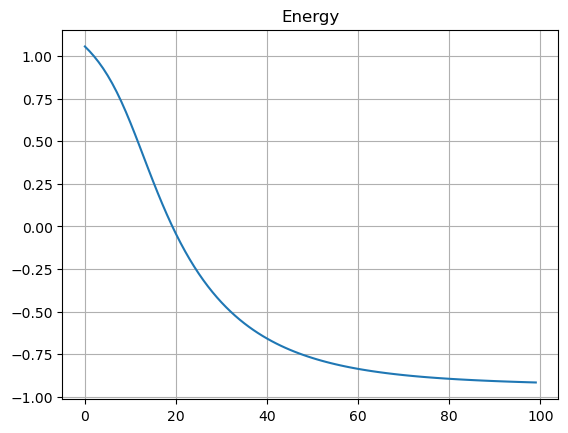

In [172]:
plt.plot(energies); plt.title('Energy'); plt.grid(); plt.show()

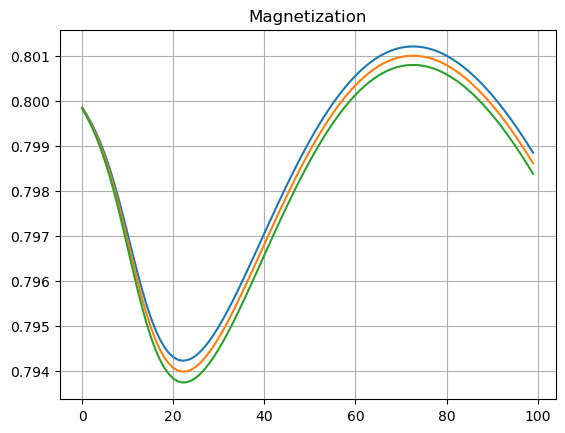

In [173]:
plt.plot(magnetizations); plt.title("Magnetization"); plt.grid(); plt.show()

In [100]:
import numpy as np
from scipy.optimize import minimize

Hm = H.to_matrix()

constraints = [
    SparsePauliOp(["XII"]).to_matrix(),
    SparsePauliOp(["IXI"]).to_matrix(),
    SparsePauliOp(["IIX"]).to_matrix(),
]

targets = np.array([
    target,
    target,
    target
])

dim = Hm.shape[0]


def normalize(x):

    n = np.linalg.norm(x)

    if n < 1e-14:
        return None

    return x / n


def energy(x):

    psi = normalize(x)

    return np.vdot(
        psi,
        Hm @ psi
    ).real


#
# equality constraints
#

cons = []

#
# norm = 1
#

cons.append({
    "type": "eq",
    "fun": lambda x:
        np.linalg.norm(x)**2 - 1.0
})

#
# <C_k> = target_k
#

for Ck, tk in zip(
    constraints,
    targets
):

    cons.append({
        "type": "eq",
        "fun": lambda x, Ck=Ck, tk=tk:
            np.vdot(
                normalize(x),
                Ck @ normalize(x)
            ).real - tk
    })


best_E = np.inf
best_psi = None

rng = np.random.default_rng(1234)

for trial in range(50):

    x0 = rng.normal(
        size=dim
    )

    x0 /= np.linalg.norm(x0)

    result = minimize(
        energy,
        x0,
        method="SLSQP",
        constraints=cons,
        options={
            "maxiter": 10000,
            "ftol": 1e-12
        }
    )

    if result.success:

        E = energy(result.x)

        if E < best_E:

            best_E = E

            best_psi = normalize(
                result.x
            )

print()
print("best energy =", best_E)

print()
print("constraints")

for i, Ck in enumerate(
    constraints
):

    value = np.vdot(
        best_psi,
        Ck @ best_psi
    ).real

    print(
        i,
        value,
        "target=",
        targets[i]
    )


best energy = -0.9369316876855056

constraints
0 0.799999999999821 target= 0.8
1 0.7999999999998355 target= 0.8
2 0.7999999999997371 target= 0.8


In [28]:
evals = np.linalg.eigvalsh(
    H_eff.to_matrix()
)

print("Exact spectrum")

print(np.round(evals,2))

Exact spectrum
[-3.46 -2.   -2.   -0.   -0.    0.    3.46  4.  ]


In [30]:
G = H_eff

In [32]:
psi = Statevector(circuit).data

vectors = []

for i in range(basis.size):

    P = basis.operator(i).to_matrix()

    v = P @ psi

    #
    # remove radial component
    #
    v -= psi * np.vdot(psi, v)

    vectors.append(
        np.real(v)
    )

T = np.column_stack(vectors)

print(
    "ITE tangent rank =",
    np.linalg.matrix_rank(
        T,
        tol=1e-10
    )
)

ITE tangent rank = 7


In [34]:
len(basis.paulis)

24

In [36]:
import numpy as np


def pauli_to_symplectic(label):

    n = len(label)

    x = np.zeros(
        n,
        dtype=np.uint8
    )

    z = np.zeros(
        n,
        dtype=np.uint8
    )

    for i, p in enumerate(label):

        if p == "X":
            x[i] = 1

        elif p == "Z":
            z[i] = 1

        elif p == "Y":
            x[i] = 1
            z[i] = 1

    return x, z


def op_to_symplectic(op):

    #
    # attenzione:
    # qui assumiamo che ogni operatore
    # della base sia una singola stringa Pauli
    #
    label = op.paulis[0].to_label()

    x, z = pauli_to_symplectic(
        label
    )

    return np.concatenate(
        [x, z]
    )


def gf2_rank(M):

    M = (
        M.copy()
        .astype(np.uint8)
    )

    nrows, ncols = M.shape

    rank = 0
    col = 0

    while (
        rank < nrows
        and col < ncols
    ):

        pivot = None

        for r in range(
            rank,
            nrows
        ):

            if M[r, col]:
                pivot = r
                break

        if pivot is None:
            col += 1
            continue

        M[[rank, pivot]] = (
            M[[pivot, rank]]
        )

        for r in range(nrows):

            if (
                r != rank
                and M[r, col]
            ):
                M[r] ^= M[rank]

        rank += 1
        col += 1

    return rank


#
# build symplectic matrix
#

Ssym = np.vstack([
    op_to_symplectic(
        basis.operator(i)
    )
    for i in range(
        basis.size
    )
])

print(
    "number of operators =",
    basis.size
)

print(
    "symplectic rank =",
    gf2_rank(Ssym)
)

print(
    "max possible =",
    2 * len(
        basis.operator(0)
        .paulis[0]
        .to_label()
    )
)

number of operators = 24
symplectic rank = 6
max possible = 6


In [38]:
seen = set()

for i in range(basis.size):

    op = basis.operator(i)

    for p in op.paulis:

        label = p.to_label()

        x, z = pauli_to_symplectic(label)

        key = tuple(
            np.concatenate([x, z])
        )

        seen.add(key)

print(
    "distinct symplectic vectors =",
    len(seen)
)

distinct symplectic vectors = 45


In [40]:
def pauli_to_symplectic(label):

    n = len(label)

    x = np.zeros(n, dtype=np.uint8)
    z = np.zeros(n, dtype=np.uint8)

    for i, p in enumerate(label):

        if p == "X":
            x[i] = 1

        elif p == "Y":
            x[i] = 1
            z[i] = 1

        elif p == "Z":
            z[i] = 1

    return x, z

In [42]:
pairs = []

for i in range(basis.size):

    op = basis.operator(i)

    if len(op.paulis) != 1:
        continue

    vin = symplectic_vector(
        op.paulis[0].to_label()
    )

    comm = CommutatorBasis.commutator(
        H_eff,
        op
    )

    if comm is None:
        continue

    for p in comm.paulis:

        vout = symplectic_vector(
            p.to_label()
        )

        pairs.append(
            (
                vin.copy(),
                vout.copy()
            )
        )

print(
    "number of pairs =",
    len(pairs)
)

NameError: name 'symplectic_vector' is not defined

In [325]:
unique_pairs = set()

for vin, vout in pairs:

    unique_pairs.add(
        (
            tuple(vin),
            tuple(vout)
        )
    )

print(
    "unique pairs =",
    len(unique_pairs)
)

for vin, vout in sorted(unique_pairs):

    print(vin, "->", vout)

unique pairs = 18
(0, 0, 0, 0, 0, 1) -> (0, 0, 1, 0, 0, 1)
(0, 0, 0, 0, 1, 0) -> (0, 1, 0, 0, 1, 0)
(0, 0, 0, 1, 0, 0) -> (1, 0, 0, 1, 0, 0)
(0, 0, 1, 0, 0, 0) -> (0, 0, 1, 0, 1, 1)
(0, 0, 1, 0, 0, 0) -> (0, 0, 1, 1, 0, 1)
(0, 0, 1, 0, 0, 1) -> (0, 0, 0, 0, 0, 1)
(0, 0, 1, 0, 0, 1) -> (0, 0, 1, 0, 1, 0)
(0, 0, 1, 0, 0, 1) -> (0, 0, 1, 1, 0, 0)
(0, 1, 0, 0, 0, 0) -> (0, 1, 0, 0, 1, 1)
(0, 1, 0, 0, 0, 0) -> (0, 1, 0, 1, 1, 0)
(0, 1, 0, 0, 1, 0) -> (0, 0, 0, 0, 1, 0)
(0, 1, 0, 0, 1, 0) -> (0, 1, 0, 0, 0, 1)
(0, 1, 0, 0, 1, 0) -> (0, 1, 0, 1, 0, 0)
(1, 0, 0, 0, 0, 0) -> (1, 0, 0, 1, 0, 1)
(1, 0, 0, 0, 0, 0) -> (1, 0, 0, 1, 1, 0)
(1, 0, 0, 1, 0, 0) -> (0, 0, 0, 1, 0, 0)
(1, 0, 0, 1, 0, 0) -> (1, 0, 0, 0, 0, 1)
(1, 0, 0, 1, 0, 0) -> (1, 0, 0, 0, 1, 0)


In [329]:
diffs = []

for vin, vout in unique_pairs:

    vin = np.array(vin, dtype=np.uint8)
    vout = np.array(vout, dtype=np.uint8)

    diffs.append(
        np.bitwise_xor(vin, vout)
    )

#
# rimuovi duplicati
#
diffs = np.unique(
    np.array(diffs),
    axis=0
)

print("generators:")
print(diffs)

generators:
[[0 0 0 0 1 1]
 [0 0 0 1 0 1]
 [0 0 0 1 1 0]
 [0 0 1 0 0 0]
 [0 1 0 0 0 0]
 [1 0 0 0 0 0]]


In [331]:
def gf2_rank(M):

    M = M.copy().astype(np.uint8)

    nrows, ncols = M.shape

    rank = 0
    col = 0

    while rank < nrows and col < ncols:

        pivot = None

        for r in range(rank, nrows):

            if M[r, col]:
                pivot = r
                break

        if pivot is None:
            col += 1
            continue

        M[[rank, pivot]] = M[[pivot, rank]]

        for r in range(nrows):

            if r != rank and M[r, col]:
                M[r] ^= M[rank]

        rank += 1
        col += 1

    return rank


r = gf2_rank(diffs)

print("rank =", r)
print("reachable states =", 2**r)

rank = 5
reachable states = 32


In [40]:
import numpy as np
from itertools import product


#
# generatori simplessici di H
#

generators = []

for p in H_eff.paulis:

    x, z = pauli_to_symplectic(
        p.to_label()
    )

    generators.append(
        np.concatenate([x, z]) % 2
    )

generators = np.array(
    generators,
    dtype=np.uint8
)

r = len(generators)

#
# tutti i vettori simplessici
# presenti nella closure
#

closure = set()

for i in range(basis.size):

    op = basis.operator(i)

    for p in op.paulis:

        x, z = pauli_to_symplectic(
            p.to_label()
        )

        closure.add(
            tuple(
                np.concatenate([x, z]) % 2
            )
        )

print(
    "closure size =",
    len(closure)
)

#
# scegliamo un seed
# (primo Pauli della closure)
#

v0 = np.array(
    next(iter(closure)),
    dtype=np.uint8
)

#
# costruzione affine
# v0 + span(H)
#

affine = set()

for coeffs in product(
    [0, 1],
    repeat=r
):

    v = v0.copy()

    for c, g in zip(
        coeffs,
        generators
    ):

        if c:
            v ^= g

    affine.add(
        tuple(v)
    )

print(
    "affine size =",
    len(affine)
)

#
# confronto
#

missing = affine - closure
extra   = closure - affine

print(
    "missing from closure =",
    len(missing)
)

print(
    "extra in closure =",
    len(extra)
)

closure size = 62
affine size = 32
missing from closure = 2
extra in closure = 32
